# Single-Cell Immune Profiling with Scanpy
**Question:** Which broad immune-cell expression patterns are present in PBMC3k,
and how much do cell groupings change when Leiden resolution increases from 0.4 to 0.8?

**Execution status at delivery:** the PBMC analysis has NOT run locally. Scanpy
installation was blocked by PyPI DNS access. No PBMC results are prefilled.
This notebook is self-contained. Run cells **1–10** in order in a fresh Colab
Python runtime; cell **11** optionally downloads your generated results ZIP.
CPU is sufficient. Selecting a GPU does not accelerate these CPU Scanpy calls.

## Biological primer
**Peripheral blood mononuclear cells (PBMCs)** are blood immune cells with a
single, non-lobed nucleus, including T cells, B cells, natural killer (NK)
cells, and monocytes. This preparation can also contain platelets or other
contaminants. **Single-cell RNA sequencing (scRNA-seq)** measures sampled RNA
molecules separately for individual captured cells. RNA abundance is an
imperfect snapshot of gene activity, not a direct measurement of protein or function.
A barcode identifies a droplet/cell; a **unique molecular identifier (UMI)**
helps count molecules rather than PCR copies. A zero can reflect low sampling,
not necessarily biological absence.

Our matrix has **cells as rows and genes as columns**. Entry (i, j) counts
captured molecules for gene j in cell i. These are Cell Ranger's called-cell
counts, already aligned and quantified; they are not FASTQ reads or an
unfiltered matrix containing all empty droplets.

## Provenance and credit
[10x Genomics PBMC3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-1-0):
one healthy human donor, one sample, 2,700 called cells; published May 26, 2016,
analyzed with Cell Ranger 1.1.0. Data license: **CC BY 4.0**; credit 10x Genomics
and link the source/license when sharing derived outputs. Scanpy's official
[raw loader](https://scanpy.readthedocs.io/en/stable/generated/scanpy.datasets.pbmc3k.html)
downloads a compressed 5.9 MB AnnData count file (2,700 × 32,738).

Adapted from Scanpy's official
[PBMC3k reference workflow](https://scanpy.readthedocs.io/en/stable/tutorials/basics/clustering-2017.html),
labeled **legacy** in current documentation. We reproduce its broad QC →
log-normalization → variable genes → scaling → PCA → graph → cluster/marker
pattern, not its exact published outputs. We omit nuisance-covariate regression,
use 2,000 variable genes and explicit Leiden settings, and add an immutable-count
audit, conservative annotation rules, a fixed-graph resolution comparison, and
machine-readable exports. No discovery claim is intended.
Cite Wolf, Angerer & Theis (2018), https://doi.org/10.1186/s13059-017-1382-0.
Documentation and package release pages checked October 20, 2026.

## Cell 1 — Install a pinned computational stack
Start in a **fresh runtime** before importing NumPy or Scanpy. These are explicit
version pins for this project, not a claim to use the latest releases. Installation
has not been integration-tested in this restricted environment. Python 3.11/3.12
is the intended runtime. On Colab, if imports report an ABI/version conflict,
restart the session after installation and rerun from this cell.


In [1]:
import os
import sys
import subprocess
from importlib.metadata import version, PackageNotFoundError

REQUIREMENTS = [
    "scanpy==1.11.5", "anndata==0.12.3", "numpy==2.2.6",
    "pandas==2.2.3", "scipy==1.15.3", "scikit-learn==1.6.1",
    "matplotlib==3.10.3", "seaborn==0.13.2", "numba==0.61.2",
    "umap-learn==0.5.7", "pynndescent==0.5.13", "h5py==3.14.0",
    "igraph==0.11.9", "leidenalg==0.10.2", "zarr==2.18.7",
]
print("Python version:", sys.version)

if sys.version_info < (3, 11):
    raise RuntimeError("Python 3.11 or newer is required.")

# Python 3.11–3.13 can use the existing package pins.
# Newer Python needs newer compatible packages.
if sys.version_info >= (3, 14):
    packages = [
        "scanpy[leiden,plotting]==1.12.4",
        "anndata>=0.12,<0.14", "numpy>=2.3.3,<3",
        "pandas>=2.3.3,<3", "scipy>=1.16.3,<2",
        "scikit-learn>=1.7.2,<2", "matplotlib>=3.10.7,<4",
        "seaborn>=0.13.2,<0.14", "numba>=0.63.1,<0.69",
        "umap-learn>=0.5.9,<0.6", "pynndescent>=0.5.13,<0.7",
        "h5py>=3.15.1,<4", "igraph>=0.11.9,<2",
        "leidenalg>=0.10.2,<0.12", "zarr>=2.18.7,<4",
    ]
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        "--quiet", "--prefer-binary", *packages
    ])
    REQUIREMENTS = [
        f"{r.split('==')[0]}=={version(r.split('==')[0])}"
        for r in REQUIREMENTS
    ]
needed = []
for requirement in REQUIREMENTS:
    package, expected = requirement.split("==")
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    if installed != expected:
        needed.append(requirement)
if needed:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *REQUIREMENTS])
print("Pinned packages installed. Scientific imports follow in cell 2.")


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Pinned packages installed. Scientific imports follow in cell 2.


## Cell 2 — Configuration and data structures
**AnnData** keeps the matrix and its annotations together:

| Field in this project | Contents |
|---|---|
| `adata.X` | Sparse, log-normalized expression for all retained genes |
| `adata.layers['counts']` | Original integer-valued counts, aligned to retained cells/genes |
| `adata.obs` | Cell barcode index, QC metrics, clusters, proposed identities |
| `adata.var` | Gene symbols/IDs, mitochondrial flag, variable-gene flag |
| `adata.obsm['X_pca']`, `['X_umap']` | Per-cell PCA coordinates / 2D display coordinates |
| `adata.obsp` | Cell-to-cell graph connectivity and distances |
| `adata.uns` | Settings, marker rankings, provenance |
| `adata.raw` | Deliberately unused; `.raw` is a snapshot, not a guarantee of raw counts |

A separate temporary `hvg` AnnData holds scaled variable genes for PCA.
This prevents accidentally ranking markers on scaled values. The original
downloaded matrix is saved separately before any filtering. Output directories
have unique run IDs so a failed rerun cannot masquerade as an earlier success.


In [2]:
os.environ["NUMBA_NUM_THREADS"] = "2"
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"
import json
import random
import time
import hashlib
import platform
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import scanpy as sc
from sklearn.metrics import adjusted_rand_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sc.settings.n_jobs = 2
sc.settings.verbosity = 2
sc.settings.set_figure_params(dpi=100, dpi_save=160, facecolor="white")
START = time.perf_counter()
BASE = Path.cwd() / "pbmc3k_runs"
RUN = BASE / datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ")
FIG = RUN / "figures"
TABLE = RUN / "tables"
for directory in (FIG, TABLE, BASE / "data"):
    directory.mkdir(parents=True, exist_ok=True)
sc.settings.datasetdir = BASE / "data"
CFG = dict(seed=SEED, min_genes=200, max_genes_exclusive=2500,
           max_mt_pct_exclusive=5.0, min_cells_per_gene=3, target_sum=10000,
           n_hvg=2000, n_pcs=40, n_neighbors=10,
           resolutions=[0.4, 0.8], stable_fraction=0.90, split_fraction=0.10)
KEYS = ["leiden_0_4", "leiden_0_8"]
def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")
write_json(RUN / "config.json", CFG)
write_json(RUN / "run_status.json", {"status": "started", "pbmc_analysis_complete": False})
versions = {r.split("==")[0]: version(r.split("==")[0]) for r in REQUIREMENTS}
write_json(RUN / "environment.json", {"python": sys.version, "platform": platform.platform(),
           "packages": versions, "execution_device": "CPU"})
(RUN / "requirements-resolved.txt").write_text(
    subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True), encoding="utf-8")
print("Results directory:", RUN)
print("CPU workflow; seed:", SEED)


Results directory: /content/pbmc3k_runs/run_20261020T174202_091744Z
CPU workflow; seed: 42


## Cell 3 — Audit helpers
The QC pass rule is explicit: at least 200 detected genes, fewer than 2,500
detected genes, and less than 5% mitochondrial counts. These historical PBMC3k
reference thresholds remove low-complexity profiles, unusually complex profiles
that may include doublets, and profiles with high mitochondrial fraction that
may reflect stress/damage. They are dataset-specific heuristics, not universal
biological cutoffs or a validated doublet detector. Total UMI counts are plotted
and reported but have **no additional hard threshold** here.
Mitochondrial percentage is computed against all input genes before gene filtering.


In [3]:
def qc_decisions(obs, config):
    """Return auditable, overlapping failure flags and the joint pass mask."""
    flags = pd.DataFrame(index=obs.index)
    flags["fail_low_genes"] = obs["n_genes_by_counts"] < config["min_genes"]
    flags["fail_high_genes"] = obs["n_genes_by_counts"] >= config["max_genes_exclusive"]
    flags["fail_mt"] = obs["pct_counts_mt"] >= config["max_mt_pct_exclusive"]
    flags["qc_pass"] = ~flags.any(axis=1)
    return flags

def sparse_fingerprint(matrix):
    """Fingerprint values plus axes/structure; detect accidental count mutation."""
    matrix = sp.csr_matrix(matrix).copy()
    matrix.sort_indices()
    digest = hashlib.sha256()
    for arr in (np.asarray(matrix.shape, dtype=np.int64), matrix.indptr, matrix.indices, matrix.data):
        digest.update(np.ascontiguousarray(arr).tobytes())
    return digest.hexdigest()

def partition_comparison(low, high, config):
    """Use cell membership, not cluster ID equality, to describe changes."""
    low, high = pd.Series(low, dtype="string"), pd.Series(high, dtype="string")
    assert low.index.equals(high.index), "Both partitions must use the same cell order."
    assert not low.isna().any() and not high.isna().any()
    counts = pd.crosstab(low, high)
    fractions = counts.div(counts.sum(axis=1), axis=0)
    rows = []
    for cluster in counts.index:
        main = counts.loc[cluster].idxmax()
        retained = float(fractions.loc[cluster, main])
        purity = float(counts.loc[cluster, main] / counts[main].sum())
        large_children = int((fractions.loc[cluster] >= config["split_fraction"]).sum())
        stable = retained >= config["stable_fraction"] and purity >= config["stable_fraction"]
        change = "stable one-to-one" if stable else (
            "split across >=2 substantial groups" if large_children >= 2 else "boundary shift / merge")
        rows.append(dict(low_cluster=str(cluster), cells=int(counts.loc[cluster].sum()),
            dominant_high_cluster=str(main), dominant_fraction=retained,
            dominant_child_purity=purity, children_at_least_10pct=large_children, change=change))
    return counts, fractions, pd.DataFrame(rows), float(adjusted_rand_score(low, high))

def save_figure(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)


## Cell 4 — Download raw counts and inspect quality
Uses `sc.datasets.pbmc3k()`, never `pbmc3k_processed()`. Data must be finite,
nonnegative, and integer-valued. Download errors stop execution; no synthetic
replacement is silently substituted. On failure, retry this cell once network
access is restored. Expected dimensions below are documented source metadata,
not a claimed result from this delivered notebook.


In [4]:
raw = sc.datasets.pbmc3k()
raw.var_names_make_unique()
raw.X = sp.csr_matrix(raw.X)
assert raw.shape == (2700, 32738), f"Unexpected source dimensions: {raw.shape}"
assert np.isfinite(raw.X.data).all() and (raw.X.data >= 0).all()
assert np.allclose(raw.X.data, np.rint(raw.X.data)), "Expected unnormalized UMI counts."
input_fingerprint = sparse_fingerprint(raw.X)
raw.write_h5ad(RUN / "pbmc3k_input_counts.h5ad", compression="gzip")
raw.var["mt"] = raw.var_names.str.startswith("MT-")
assert raw.var["mt"].any(), "Mitochondrial gene naming must be inspected."
sc.pp.calculate_qc_metrics(raw, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
QC = ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
flags = qc_decisions(raw.obs, CFG)
raw.obs = raw.obs.join(flags)
raw.obs.to_csv(TABLE / "qc_all_cells.csv", index_label="cell_barcode")
print("Downloaded count matrix:", raw.shape)
print(raw.obs[QC].describe().round(2).to_string())


try downloading from url
https://falexwolf.de/data/pbmc3k_raw.h5ad
... this may take a while but only happens once


  0%|          | 0.00/5.58M [00:00<?, ?B/s]

Downloaded count matrix: (2700, 32738)
       total_counts  n_genes_by_counts  pct_counts_mt
count       2700.00            2700.00        2700.00
mean        2366.90             846.99           2.22
std         1094.26             282.10           1.17
min          548.00             212.00           0.00
25%         1757.75             690.00           1.54
50%         2197.00             817.00           2.03
75%         2763.00             953.25           2.64
max        15844.00            3422.00          22.57


## Cell 5 — Filter and compare before/after
Failure counts overlap; do not add them to obtain total removed cells. A
sequential waterfall and the final joint mask are both exported. Genes detected
in fewer than three retained cells are removed after cell QC. Before/after QC
values use the same original count denominator for an honest comparison.


filtered out 19082 genes that are detected in less than 3 cells


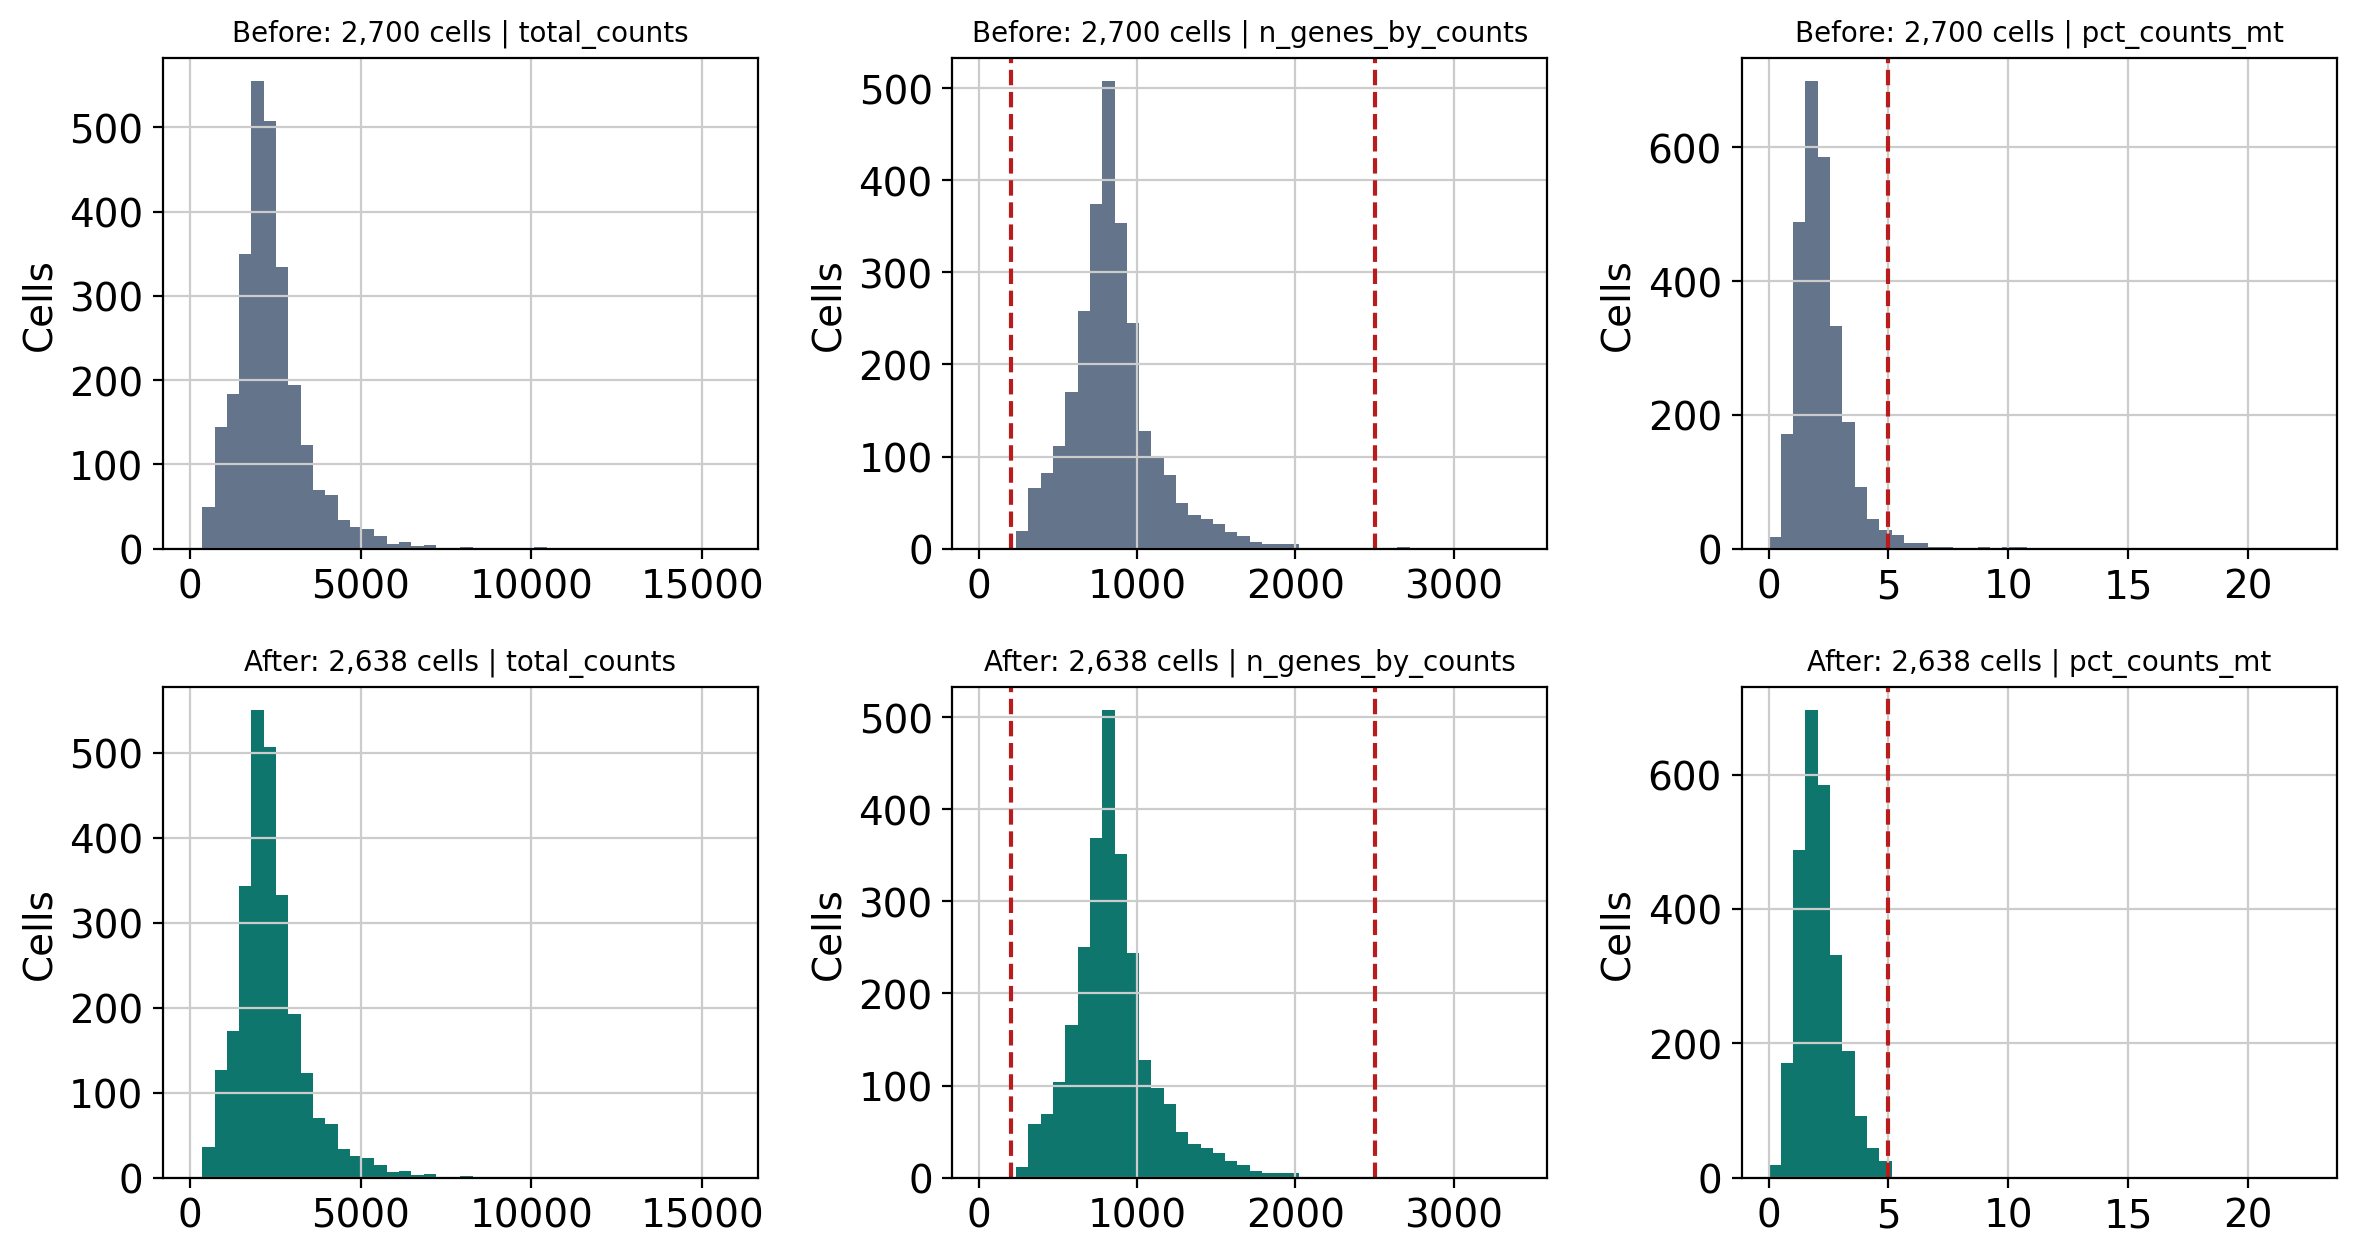

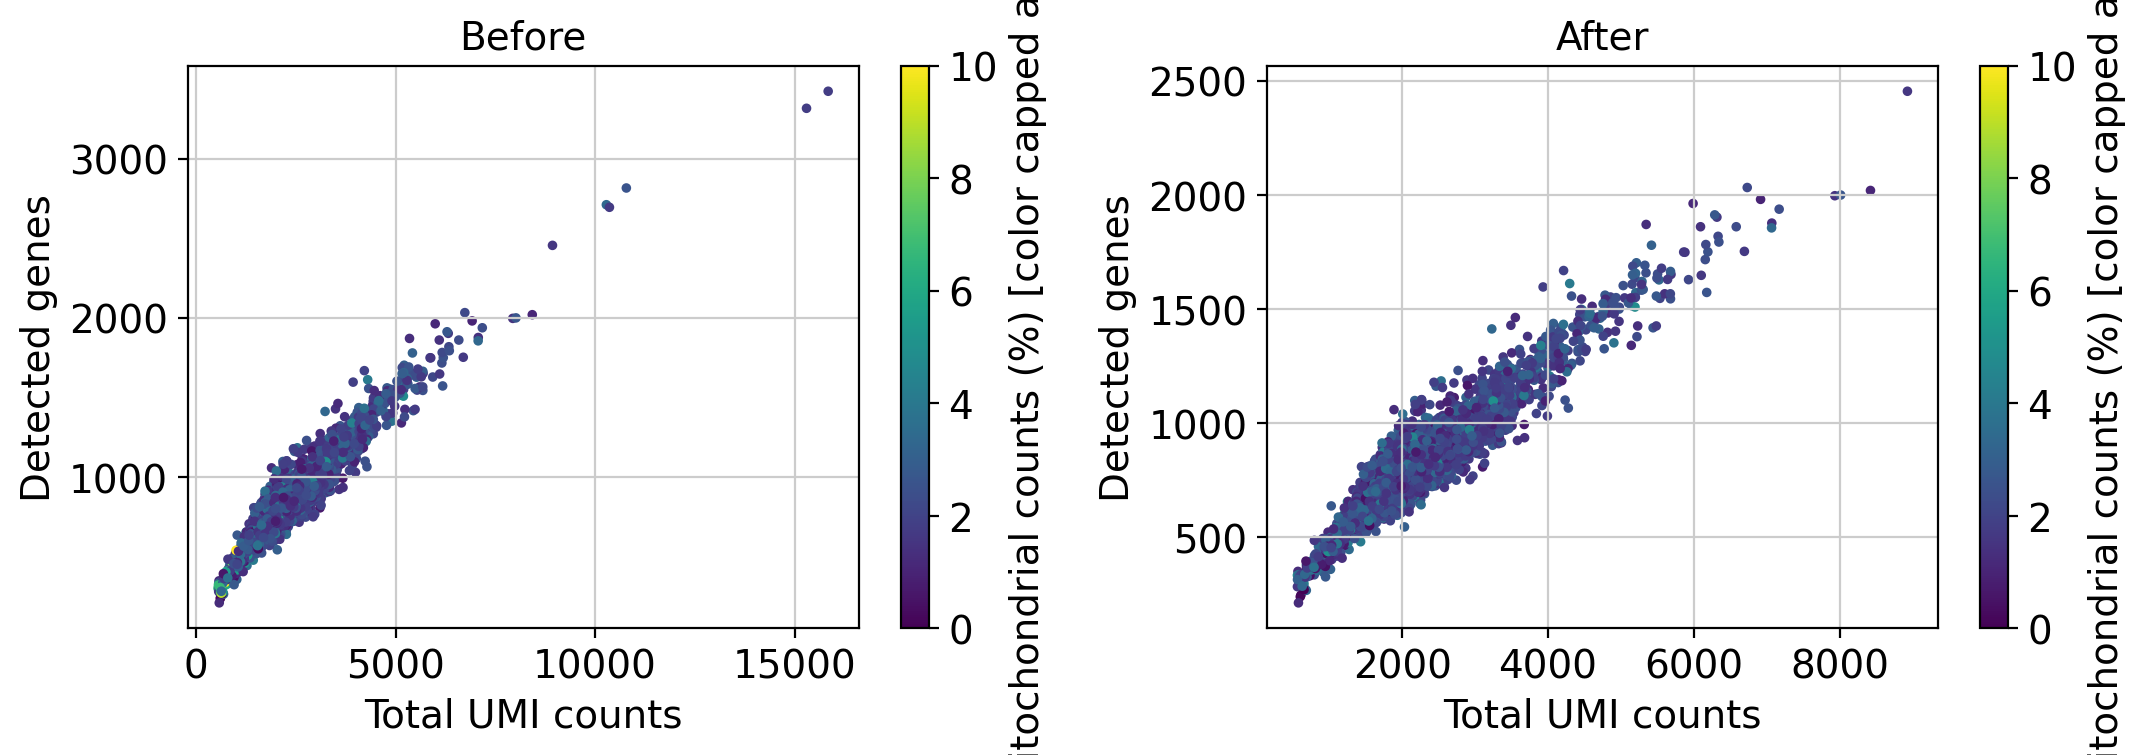

{
  "input_cells": 2700,
  "input_genes": 32738,
  "retained_cells": 2638,
  "removed_cells": 62,
  "retained_genes": 13656,
  "input_count_fingerprint": "f35c2d1a9493af8a1b0351a6c4f66343f2f286febd1446ab1249ae4b2445f50a",
  "retained_count_fingerprint": "cb146063236edb717022edc43fed234bd6dada37966ee7f945781a63421b7a45",
  "overlapping_failures": {
    "fail_low_genes": 0,
    "fail_high_genes": 5,
    "fail_mt": 57
  }
}


In [5]:
passed = raw.obs["qc_pass"].to_numpy()
waterfall = [("input", raw.n_obs)]
mask = np.ones(raw.n_obs, dtype=bool)
for reason in ("fail_low_genes", "fail_high_genes", "fail_mt"):
    mask &= ~raw.obs[reason].to_numpy()
    waterfall.append((f"after_{reason}", int(mask.sum())))
assert np.array_equal(mask, passed)
pd.DataFrame(waterfall, columns=["stage", "cells_remaining"]).to_csv(TABLE / "qc_waterfall.csv", index=False)
adata = raw[passed].copy()
assert adata.n_obs > 100, "Too few cells survive; inspect QC before proceeding."
sc.pp.filter_genes(adata, min_cells=CFG["min_cells_per_gene"])
adata.layers["counts"] = adata.X.copy()
count_fingerprint = sparse_fingerprint(adata.layers["counts"])
summary = {"input_cells": int(raw.n_obs), "input_genes": int(raw.n_vars),
    "retained_cells": int(adata.n_obs), "removed_cells": int(raw.n_obs - adata.n_obs),
    "retained_genes": int(adata.n_vars), "input_count_fingerprint": input_fingerprint,
    "retained_count_fingerprint": count_fingerprint,
    "overlapping_failures": {c: int(raw.obs[c].sum()) for c in flags if c != "qc_pass"}}
qc_stats = []
for stage, frame in [("before", raw.obs), ("after", raw.obs.loc[passed])]:
    for metric in QC:
        series = frame[metric]
        qc_stats.append(dict(stage=stage, metric=metric, cells=len(frame),
            median=float(series.median()), q05=float(series.quantile(.05)),
            q95=float(series.quantile(.95)), minimum=float(series.min()), maximum=float(series.max())))
pd.DataFrame(qc_stats).to_csv(TABLE / "qc_summary.csv", index=False)
write_json(RUN / "qc_summary.json", summary)
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for j, metric in enumerate(QC):
    bins = np.linspace(0, float(raw.obs[metric].max()) + 1e-6, 45)
    for i, (stage, frame) in enumerate([("Before", raw.obs), ("After", raw.obs.loc[passed])]):
        ax = axes[i, j]
        ax.hist(frame[metric], bins=bins, color=["#64748b", "#0f766e"][i])
        ax.set_title(f"{stage}: {len(frame):,} cells | {metric}", fontsize=10)
        ax.set_ylabel("Cells")
        if metric == "n_genes_by_counts":
            for cutoff in [CFG["min_genes"], CFG["max_genes_exclusive"]]:
                ax.axvline(cutoff, color="#b91c1c", linestyle="--")
        if metric == "pct_counts_mt":
            ax.axvline(CFG["max_mt_pct_exclusive"], color="#b91c1c", linestyle="--")
fig.tight_layout()
save_figure(fig, "qc_before_after")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, stage, frame in zip(axes, ["Before", "After"], [raw.obs, raw.obs.loc[passed]]):
    points = ax.scatter(frame.total_counts, frame.n_genes_by_counts,
                        c=frame.pct_counts_mt, s=6, vmin=0, vmax=10, cmap="viridis")
    ax.set(xlabel="Total UMI counts", ylabel="Detected genes", title=stage)
    fig.colorbar(points, ax=ax, label="Mitochondrial counts (%) [color capped at 10]")
fig.tight_layout()
save_figure(fig, "qc_scatter")
print(json.dumps(summary, indent=2))
del raw


## Cell 6 — Normalize, select genes, scale, and construct a graph
Library-size normalization divides each gene count by that cell's total count
across retained genes and multiplies by 10,000. It reduces differences in
captured RNA depth; it does not remove all technical effects or recover true
molecule abundance. `log1p(x) = ln(1+x)` compresses large values while retaining zeros.

**Highly variable genes (HVGs)** vary more than expected relative to their mean.
We select 2,000 using the Seurat dispersion method on log-normalized values.
The `seurat_v3` method is different and expects counts; it is not used here.
Only HVGs are centered/scaled to unit variance (clipped at 10) in `hvg`.
**PCA** summarizes coordinated expression changes in 40 linear components.
A graph links each cell to nearby cells in PCA space using 10 neighbors.
These fixed choices were made before viewing results; they are not optimized
claims. The explained-variance plot is diagnostic. No batch correction is
applied because there is one sample. Covariates are not regressed out to avoid
silently removing biological variation; technical variation may remain.


normalizing counts per cell
    finished (0:00:03)
extracting highly variable genes
    finished (0:00:00)


/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


computing PCA
    with n_comps=40
    finished (0:00:03)


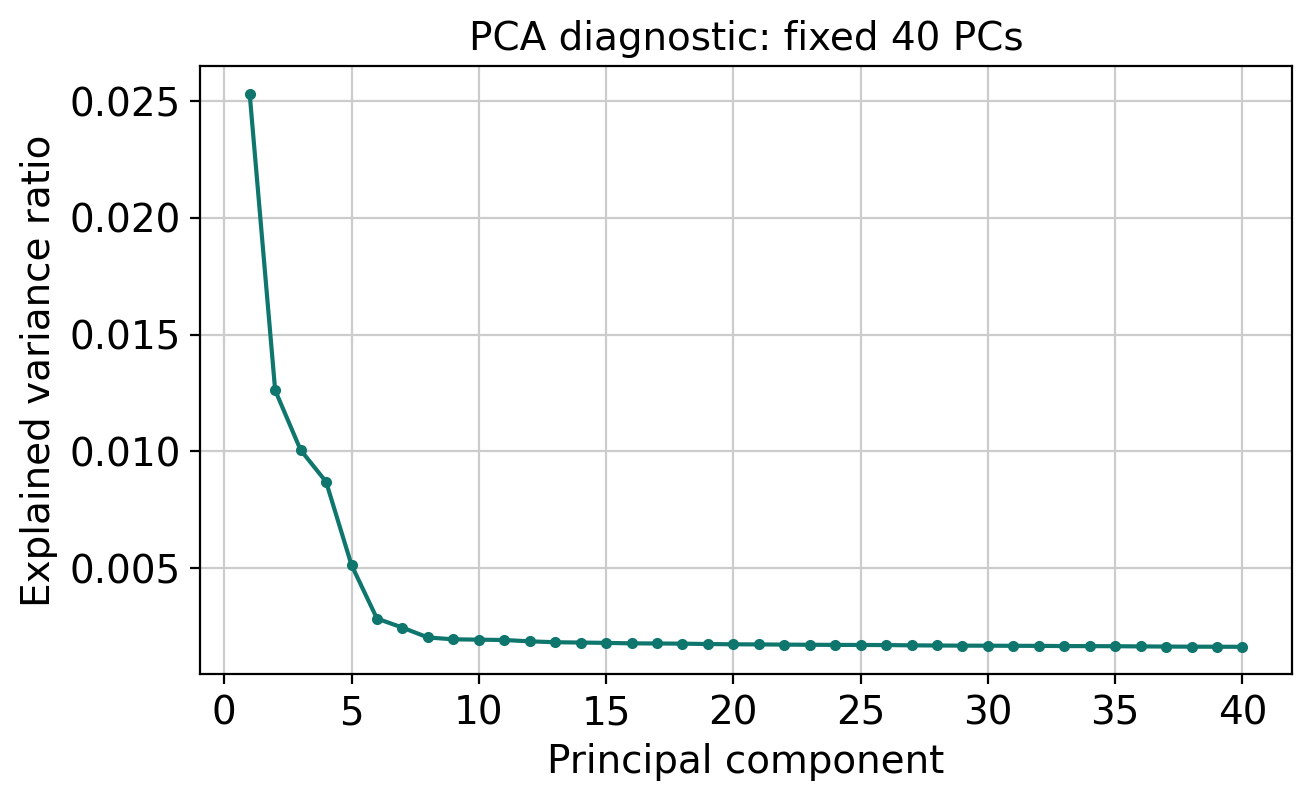

computing neighbors
    finished (0:00:36)
HVGs: 2000 | PCA: (2638, 40) | graph: (2638, 2638)


In [6]:
sc.pp.normalize_total(adata, target_sum=CFG["target_sum"])
normalized_totals = np.asarray(adata.X.sum(axis=1)).ravel()
assert np.allclose(normalized_totals, CFG["target_sum"], rtol=1e-5)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, flavor="seurat", n_top_genes=CFG["n_hvg"])
adata.var.to_csv(TABLE / "gene_metadata.csv", index_label="gene")
hvg = adata[:, adata.var["highly_variable"]].copy()
# Keep the full counts only in adata; avoid a redundant layer in the PCA workspace.
del hvg.layers["counts"]
sc.pp.scale(hvg, max_value=10)
sc.tl.pca(hvg, n_comps=CFG["n_pcs"], svd_solver="arpack", random_state=SEED)
adata.obsm["X_pca"] = hvg.obsm["X_pca"].copy()
adata.uns["pca"] = hvg.uns["pca"].copy()
loadings = np.zeros((adata.n_vars, CFG["n_pcs"]), dtype=np.float32)
loadings[adata.var["highly_variable"].to_numpy()] = hvg.varm["PCs"]
adata.varm["PCs"] = loadings
variance = hvg.uns["pca"]["variance_ratio"]
pd.DataFrame({"PC": np.arange(1, len(variance)+1), "variance_ratio": variance,
              "cumulative_variance_ratio": np.cumsum(variance)}).to_csv(TABLE / "pca_variance.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(variance)+1), variance, marker=".", color="#0f766e")
ax.set(xlabel="Principal component", ylabel="Explained variance ratio", title="PCA diagnostic: fixed 40 PCs")
save_figure(fig, "pca_variance")
sc.pp.neighbors(adata, n_neighbors=CFG["n_neighbors"], n_pcs=CFG["n_pcs"],
                use_rep="X_pca", random_state=SEED, method="umap")
graph_fingerprint = sparse_fingerprint(adata.obsp["connectivities"])
assert sparse_fingerprint(adata.layers["counts"]) == count_fingerprint
print("HVGs:", hvg.n_vars, "| PCA:", adata.obsm["X_pca"].shape,
      "| graph:", adata.obsp["connectivities"].shape)
del hvg


## Cell 7 — Leiden, UMAP, and the sensitivity experiment
**Leiden** finds connected communities in the graph. A higher resolution tends
to make finer groups; a cluster number is an arbitrary ID, not a cell-type label.
**UMAP** places cells in 2D for exploration. We compute it once and reuse the
coordinates for both panels. It does not drive clustering, prove cell identities,
preserve all distances, or establish developmental relationships.

**Adjusted Rand index (ARI)** compares whether pairs of cells stay together,
correcting for chance: 1 means identical partitions up to label names, near 0
means chance-level agreement; values can be negative. It is not classification
accuracy or biological validation. We also report the cross-tabulation because
a global score can hide rare-population changes. A stable group requires at
least 90% retention in one child AND at least 90% purity of that child. A split
requires at least two child groups each containing at least 10% of its cells.
These descriptive thresholds are declared in advance. Leiden partitions need
not be strictly nested. This experiment changes **only resolution**, not QC,
HVGs, PCA, neighbor graph, seed, Leiden backend, or UMAP settings.


running Leiden clustering


/tmp/ipykernel_2956/1916103462.py:2: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=resolution, key_added=key, random_state=SEED,


    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
computing UMAP
    finished (0:00:06)


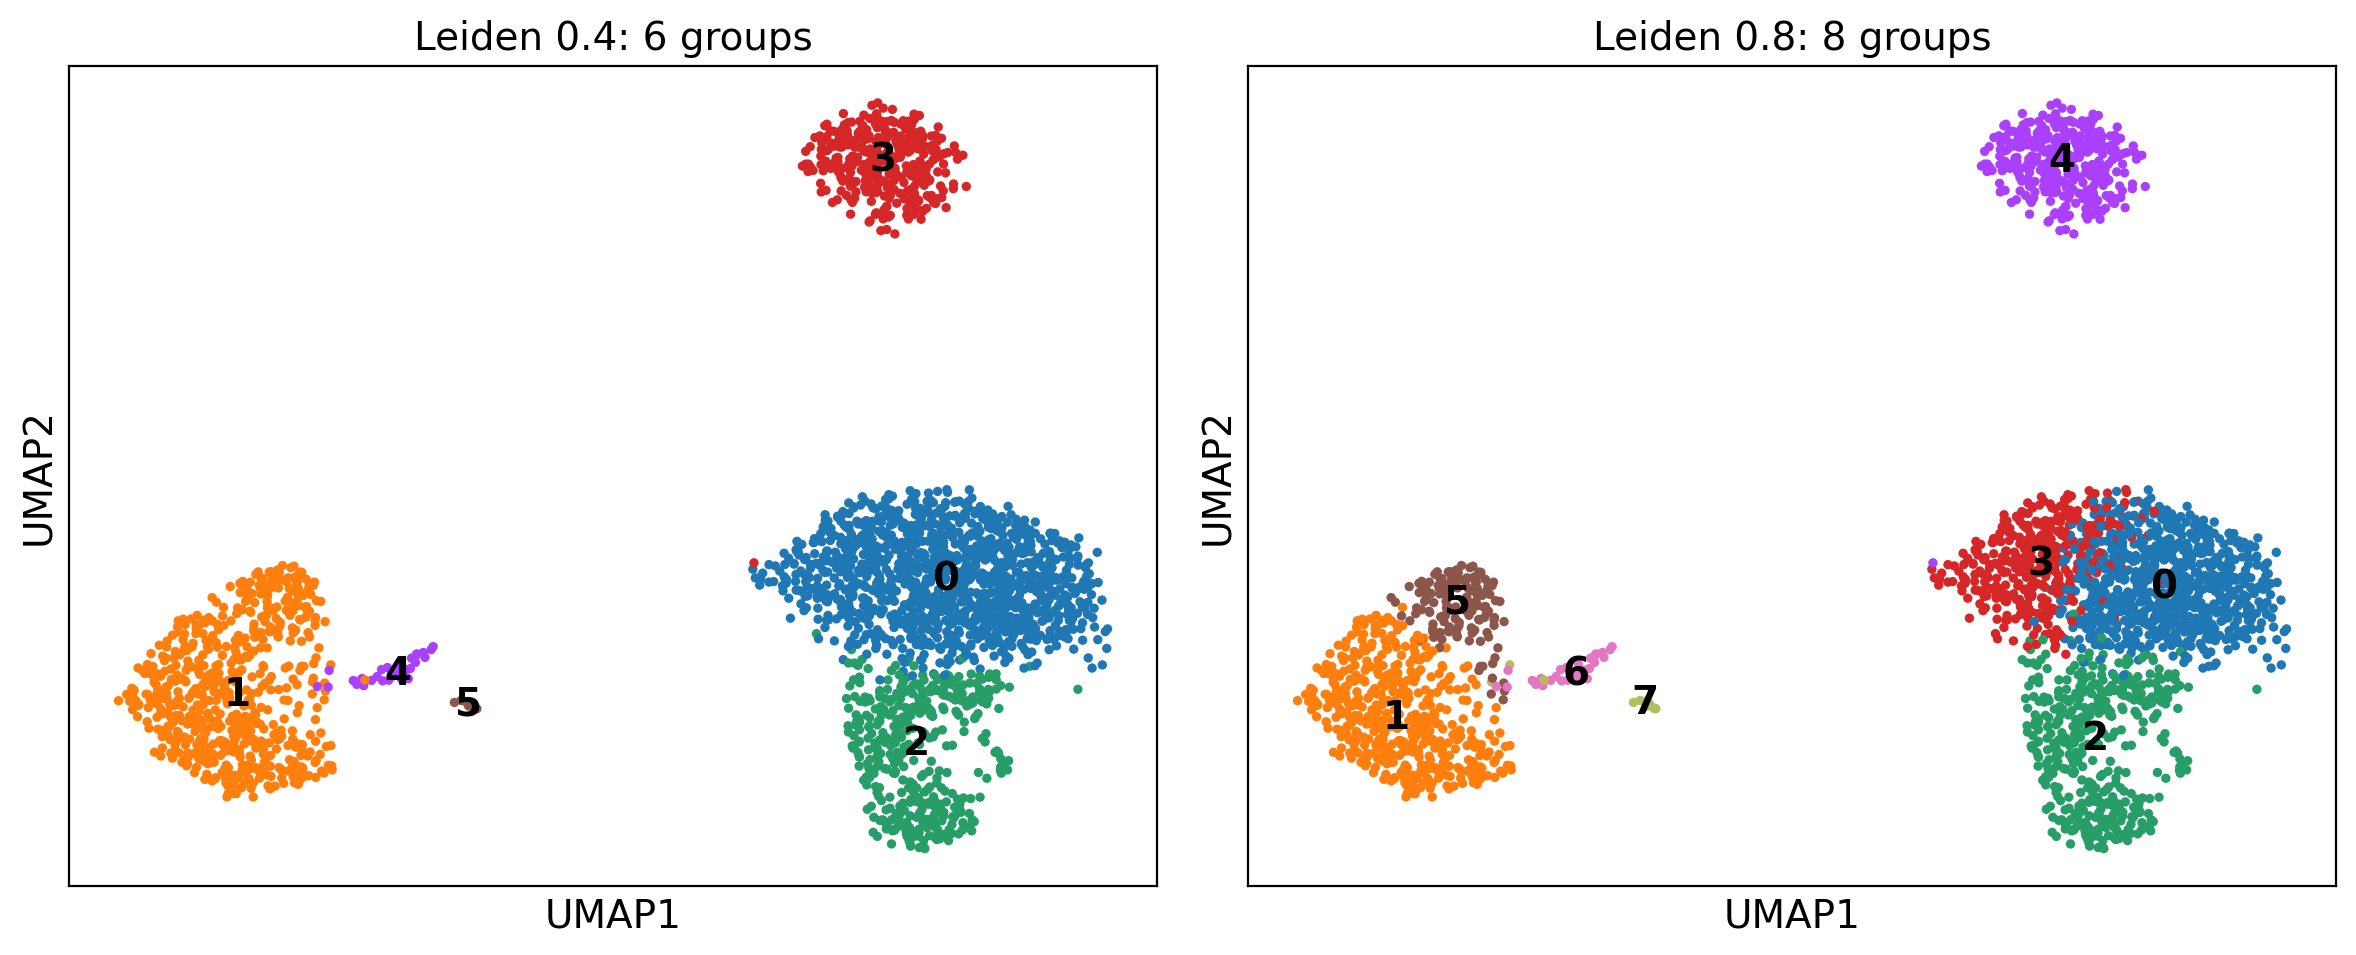

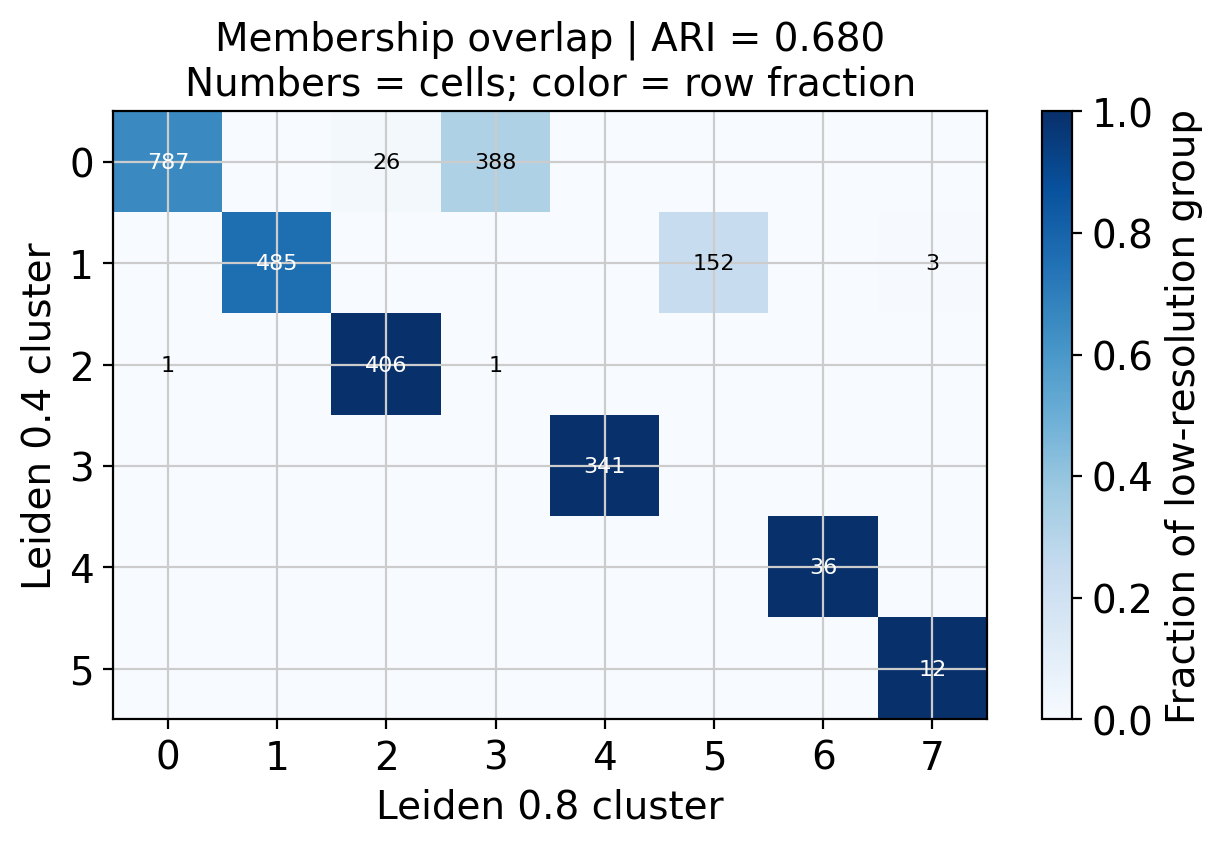

{
  "adjusted_rand_index": 0.6797473273807938,
  "clusters_at_0_4": 6,
  "clusters_at_0_8": 8,
  "graph_fingerprint": "e4733c7ee8f25326f6f8b4c6e9c0f562f4ccce4f2b240ac8172748ce481604ec",
  "preprocessing_held_fixed": true,
  "stable_low_clusters": [
    "2",
    "3",
    "4"
  ],
  "split_low_clusters": [
    "0",
    "1"
  ]
}
low_cluster  cells dominant_high_cluster  dominant_fraction  dominant_child_purity  children_at_least_10pct                              change
          0   1201                     0           0.655287               0.998731                        2 split across >=2 substantial groups
          1    640                     1           0.757812               1.000000                        2 split across >=2 substantial groups
          2    408                     2           0.995098               0.939815                        1                   stable one-to-one
          3    341                     4           1.000000               1.000000             

In [7]:
for resolution, key in zip(CFG["resolutions"], KEYS):
    sc.tl.leiden(adata, resolution=resolution, key_added=key, random_state=SEED,
                 flavor="leidenalg", directed=False, n_iterations=-1, use_weights=True)
    assert sparse_fingerprint(adata.obsp["connectivities"]) == graph_fingerprint
sc.tl.umap(adata, random_state=SEED, min_dist=0.5)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, resolution, key in zip(axes, CFG["resolutions"], KEYS):
    sc.pl.umap(adata, color=key, ax=ax, show=False, legend_loc="on data",
               title=f"Leiden {resolution}: {adata.obs[key].nunique()} groups")
fig.tight_layout()
save_figure(fig, "umap_resolutions")
cross, fractions, stability, ari = partition_comparison(adata.obs[KEYS[0]], adata.obs[KEYS[1]], CFG)
cross.to_csv(TABLE / "resolution_crosstab_counts.csv")
fractions.to_csv(TABLE / "resolution_crosstab_row_fractions.csv")
stability.to_csv(TABLE / "cluster_stability.csv", index=False)
sensitivity = {"adjusted_rand_index": ari,
    "clusters_at_0_4": int(adata.obs[KEYS[0]].nunique()),
    "clusters_at_0_8": int(adata.obs[KEYS[1]].nunique()),
    "graph_fingerprint": graph_fingerprint, "preprocessing_held_fixed": True,
    "stable_low_clusters": stability.loc[stability.change == "stable one-to-one", "low_cluster"].tolist(),
    "split_low_clusters": stability.loc[stability.change.str.startswith("split"), "low_cluster"].tolist()}
write_json(RUN / "sensitivity.json", sensitivity)
fig, ax = plt.subplots(figsize=(max(7, .7*len(cross.columns)), max(4, .5*len(cross.index))))
im = ax.imshow(fractions, vmin=0, vmax=1, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(cross.columns)), labels=cross.columns)
ax.set_yticks(range(len(cross.index)), labels=cross.index)
ax.set(xlabel="Leiden 0.8 cluster", ylabel="Leiden 0.4 cluster",
       title=f"Membership overlap | ARI = {ari:.3f}\nNumbers = cells; color = row fraction")
for i in range(len(cross.index)):
    for j in range(len(cross.columns)):
        if cross.iloc[i, j]:
            ax.text(j, i, str(cross.iloc[i, j]), ha="center", va="center",
                    color="white" if fractions.iloc[i, j] > .55 else "black", fontsize=8)
fig.colorbar(im, ax=ax, label="Fraction of low-resolution group")
save_figure(fig, "resolution_overlap")
print(json.dumps(sensitivity, indent=2))
print(stability.to_string(index=False))


## Cell 8 — Rank cluster-associated genes and inspect marker evidence
Wilcoxon rank-sum tests compare each cluster against the other cells using
unscaled, log-normalized values for **all retained genes**, not only HVGs.
Benjamini–Hochberg adjusted p-values are exported for transparency. These
rankings are exploratory: the same data selected the clusters and their markers,
and cells from one donor are not independent biological replicates.
Neither small p-values nor large fold changes establish disease effects.
The returned log fold changes are Scanpy approximations, not count-model estimates.

Broad marker panels follow the [Seurat PBMC3k reference](https://satijalab.org/seurat/articles/pbmc3k_tutorial.html)
and Scanpy's reference workflow: T (`CD3D`, `CD3E`, `IL7R`, `CD8A`);
B (`MS4A1`, `CD79A`); myeloid (`LYZ`, `CD14`, `FCGR3A`, `MS4A7`);
NK/cytotoxic (`NKG7`, `GNLY`); dendritic-like (`FCER1A`, `CST3`);
platelet-like (`PPBP`, `PF4`). Multiple markers and competing lineages matter:
NKG7 can occur in cytotoxic T cells, FCGR3A in NK cells and monocytes,
and CST3 is not specific to dendritic cells. Platelets are not immune cells.
A dot's size means fraction of cells with detected expression; its color means
mean log-normalized expression (without per-gene color rescaling).


Panel genes absent after filtering: []
ranking genes
    finished (0:00:36)


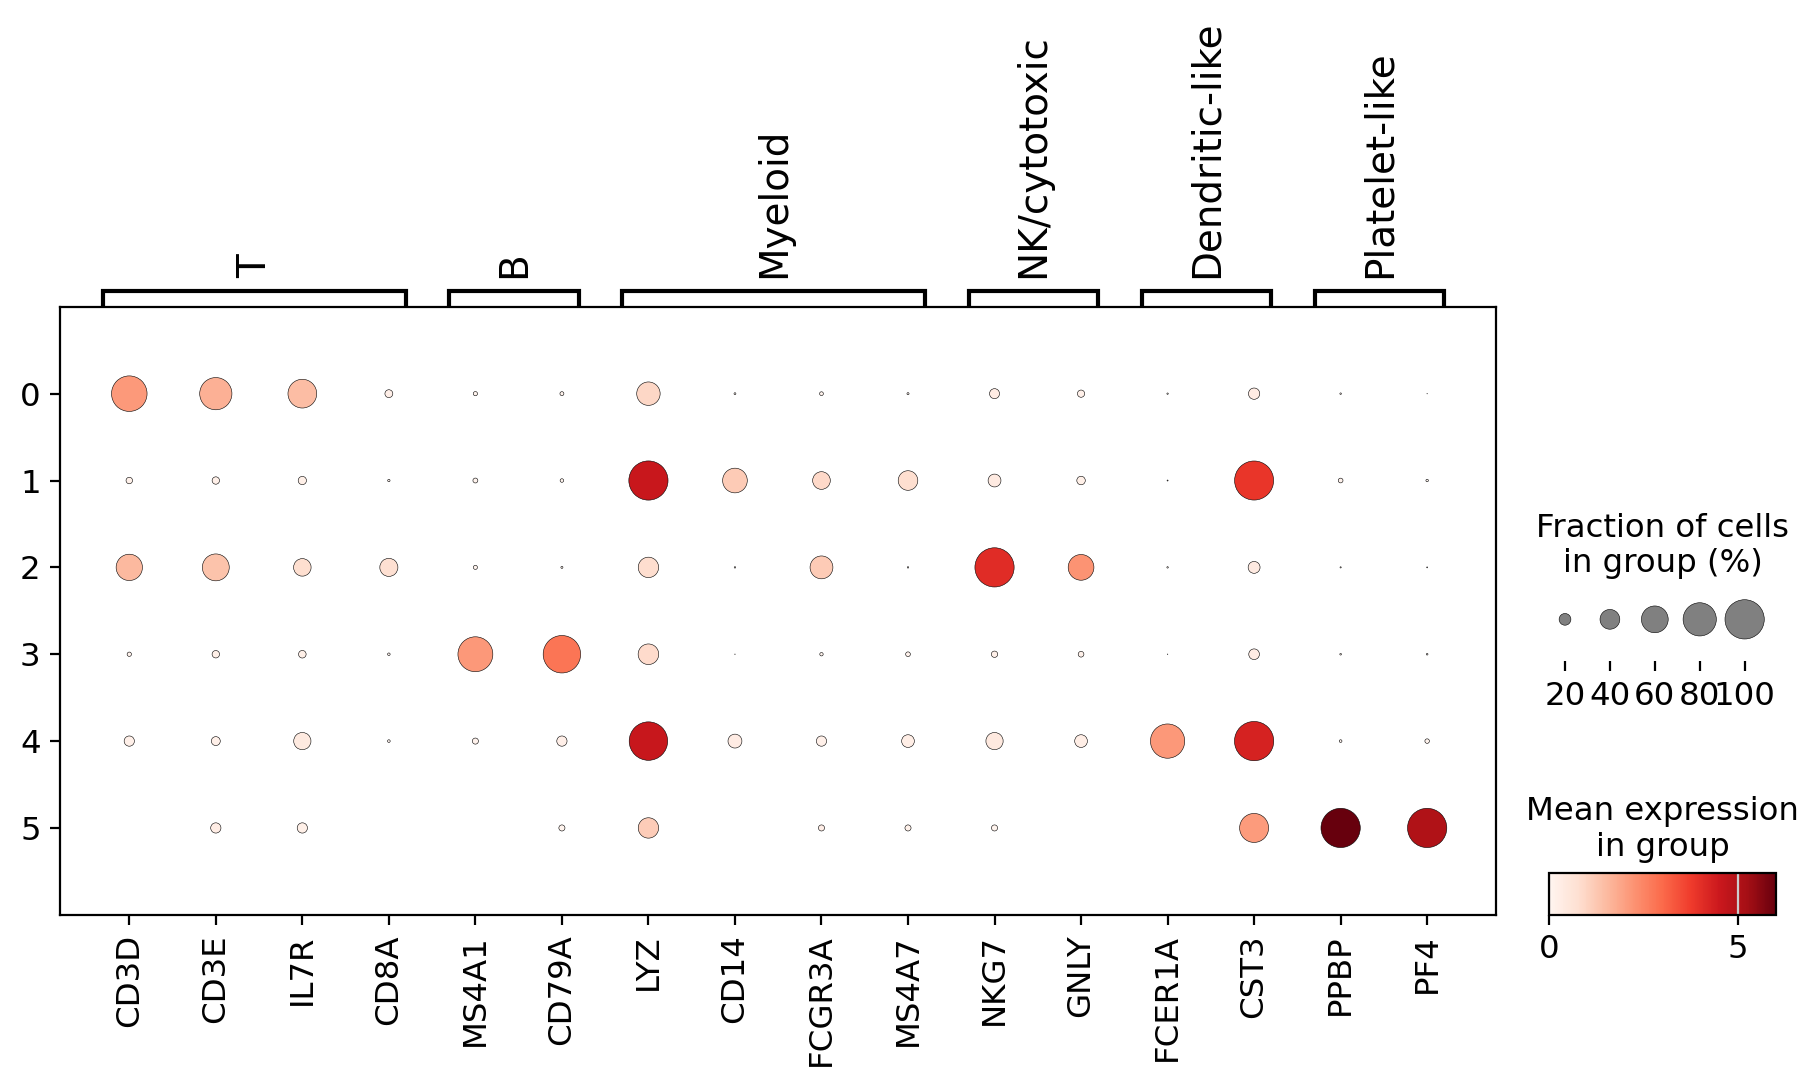

leiden_0_4 top genes:
group      names    scores
    0       LDHB 33.303223
    0      RPS12 32.526783
    0       CD3D 31.054733
    1       LST1 42.231239
    1     TYROBP 42.088432
    1     S100A9 41.812782
    2       CST7 39.927887
    2       NKG7 39.191944
    2       GZMA 38.880203
    3      CD79A 43.840023
    3      MS4A1 39.456543
    3      CD79B 35.198151
    4     FCER1A 34.555347
    4   SERPINF1 28.947451
    4    CLEC10A 26.870016
    5     ITGA2B 42.106277
    5        GP9 40.784031
    5 AP001189.4 39.618534
ranking genes
    finished (0:00:15)


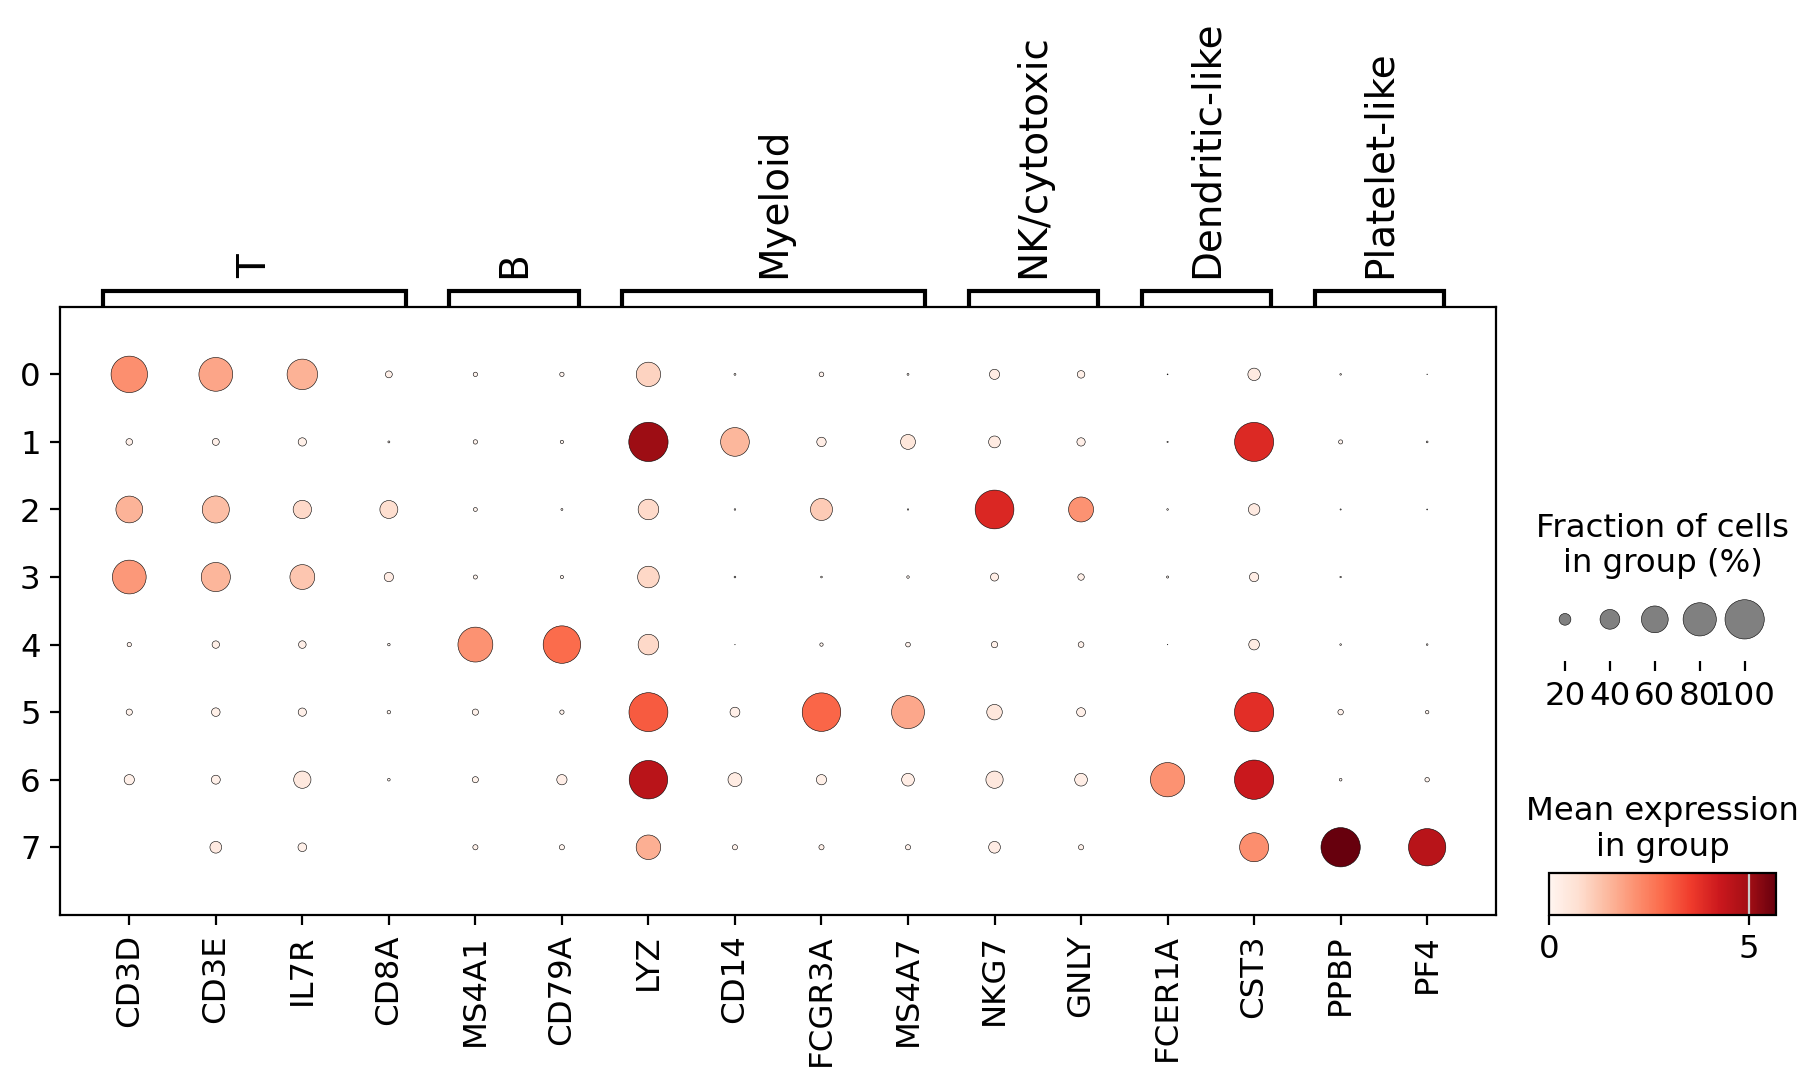

leiden_0_8 top genes:
group         names    scores
    0          LDHB 25.623699
    0          CD3D 23.452616
    0           LTB 22.947815
    1        LGALS2 42.398762
    1        S100A8 42.011784
    1        S100A9 39.361717
    2          CST7 39.544907
    2          NKG7 39.380306
    2          GZMA 39.219696
    3         RPS12 18.049372
    3         RPL32 17.971184
    3          RPS6 17.625635
    4         CD79A 43.840023
    4         MS4A1 39.456543
    4         CD79B 35.198151
    5        CDKN1C 30.070055
    5 RP11-290F20.3 29.317442
    5          HES4 28.572659
    6        FCER1A 34.555347
    6      SERPINF1 28.947451
    6       CLEC10A 26.870016
    7           GP9 43.089458
    7    AP001189.4 42.506863
    7        ITGA2B 41.061584


In [8]:
PANELS = {
    "T": ["CD3D", "CD3E", "IL7R", "CD8A"],
    "B": ["MS4A1", "CD79A"],
    "Myeloid": ["LYZ", "CD14", "FCGR3A", "MS4A7"],
    "NK/cytotoxic": ["NKG7", "GNLY"],
    "Dendritic-like": ["FCER1A", "CST3"],
    "Platelet-like": ["PPBP", "PF4"],
}
present_panels = {name: [g for g in genes if g in adata.var_names] for name, genes in PANELS.items()}
missing = sorted({g for genes in PANELS.values() for g in genes if g not in adata.var_names})
write_json(RUN / "missing_panel_markers.json", missing)
print("Panel genes absent after filtering:", missing)
marker_tables = {}
for key in KEYS:
    sc.tl.rank_genes_groups(adata, groupby=key, key_added=f"markers_{key}",
        use_raw=False, method="wilcoxon", tie_correct=True,
        corr_method="benjamini-hochberg", pts=True, n_genes=adata.n_vars)
    table = sc.get.rank_genes_groups_df(adata, group=None, key=f"markers_{key}")
    table["group"] = table["group"].astype(str)
    marker_tables[key] = table
    table.to_csv(TABLE / f"markers_{key}_all.csv.gz", index=False)
    table.groupby("group", sort=False).head(20).to_csv(TABLE / f"markers_{key}_top20.csv", index=False)
    dot = sc.pl.dotplot(adata, {k: v for k, v in present_panels.items() if v},
        groupby=key, use_raw=False, standard_scale=None, return_fig=True,
        figsize=(11, max(4, adata.obs[key].nunique()*.4)))
    dot.make_figure()
    save_figure(dot.fig, f"marker_dotplot_{key}")
    print(key, "top genes:")
    print(table.groupby("group", sort=False).head(3)[["group", "names", "scores"]].to_string(index=False))


## Cell 9 — Propose identities conservatively and connect them to stability
These are transparent **heuristic proposals**, not a trained classifier or
verified annotations. A marker supports a group if detected in at least 20%
of cells AND its mean log expression exceeds the rest by at least 0.15.
Require two supporting markers for a broad label. Both cutoffs are project
choices, not calibrated biological standards. Competing T/B/myeloid/platelet
evidence produces an explicit mixed/uncertain label. Cytotoxic evidence with
T markers remains T-like; cytotoxic evidence without T markers is only NK-like
if average CD3D/CD3E detection is below 20%. Dendritic and monocyte evidence
can overlap and is marked uncertain. Missing evidence stays unassigned.

Read the ranked markers, detection fractions, and dot plots together before
using the proposals in an interview. Labels are cluster-level summaries;
every member is not independently validated. A mixed group does not prove
that its cells are doublets. Review rare groups especially carefully.


cluster  cells          proposed_identity                     status                   supporting_markers                        top_ranked_genes
      0   1201                     T-like provisional; not validated                     CD3D; CD3E; IL7R          LDHB; RPS12; CD3D; RPS25; RPS3
      1    640      Monocyte/myeloid-like provisional; not validated       LYZ; CD14; FCGR3A; MS4A7; CST3         LST1; TYROBP; S100A9; CFD; AIF1
      2    408 T-like (cytotoxic program) provisional; not validated CD3D; CD3E; CD8A; FCGR3A; NKG7; GNLY            CST7; NKG7; GZMA; PRF1; CTSW
      3    341                     B-like provisional; not validated                         MS4A1; CD79A    CD79A; MS4A1; CD79B; TCL1A; HLA-DQA1
      4     36             Dendritic-like provisional; not validated                    LYZ; FCER1A; CST3  FCER1A; SERPINF1; CLEC10A; ENHO; CLIC2
      5     12              Platelet-like provisional; not validated                      CST3; PPBP; PF4 ITGA2B; GP9; AP001

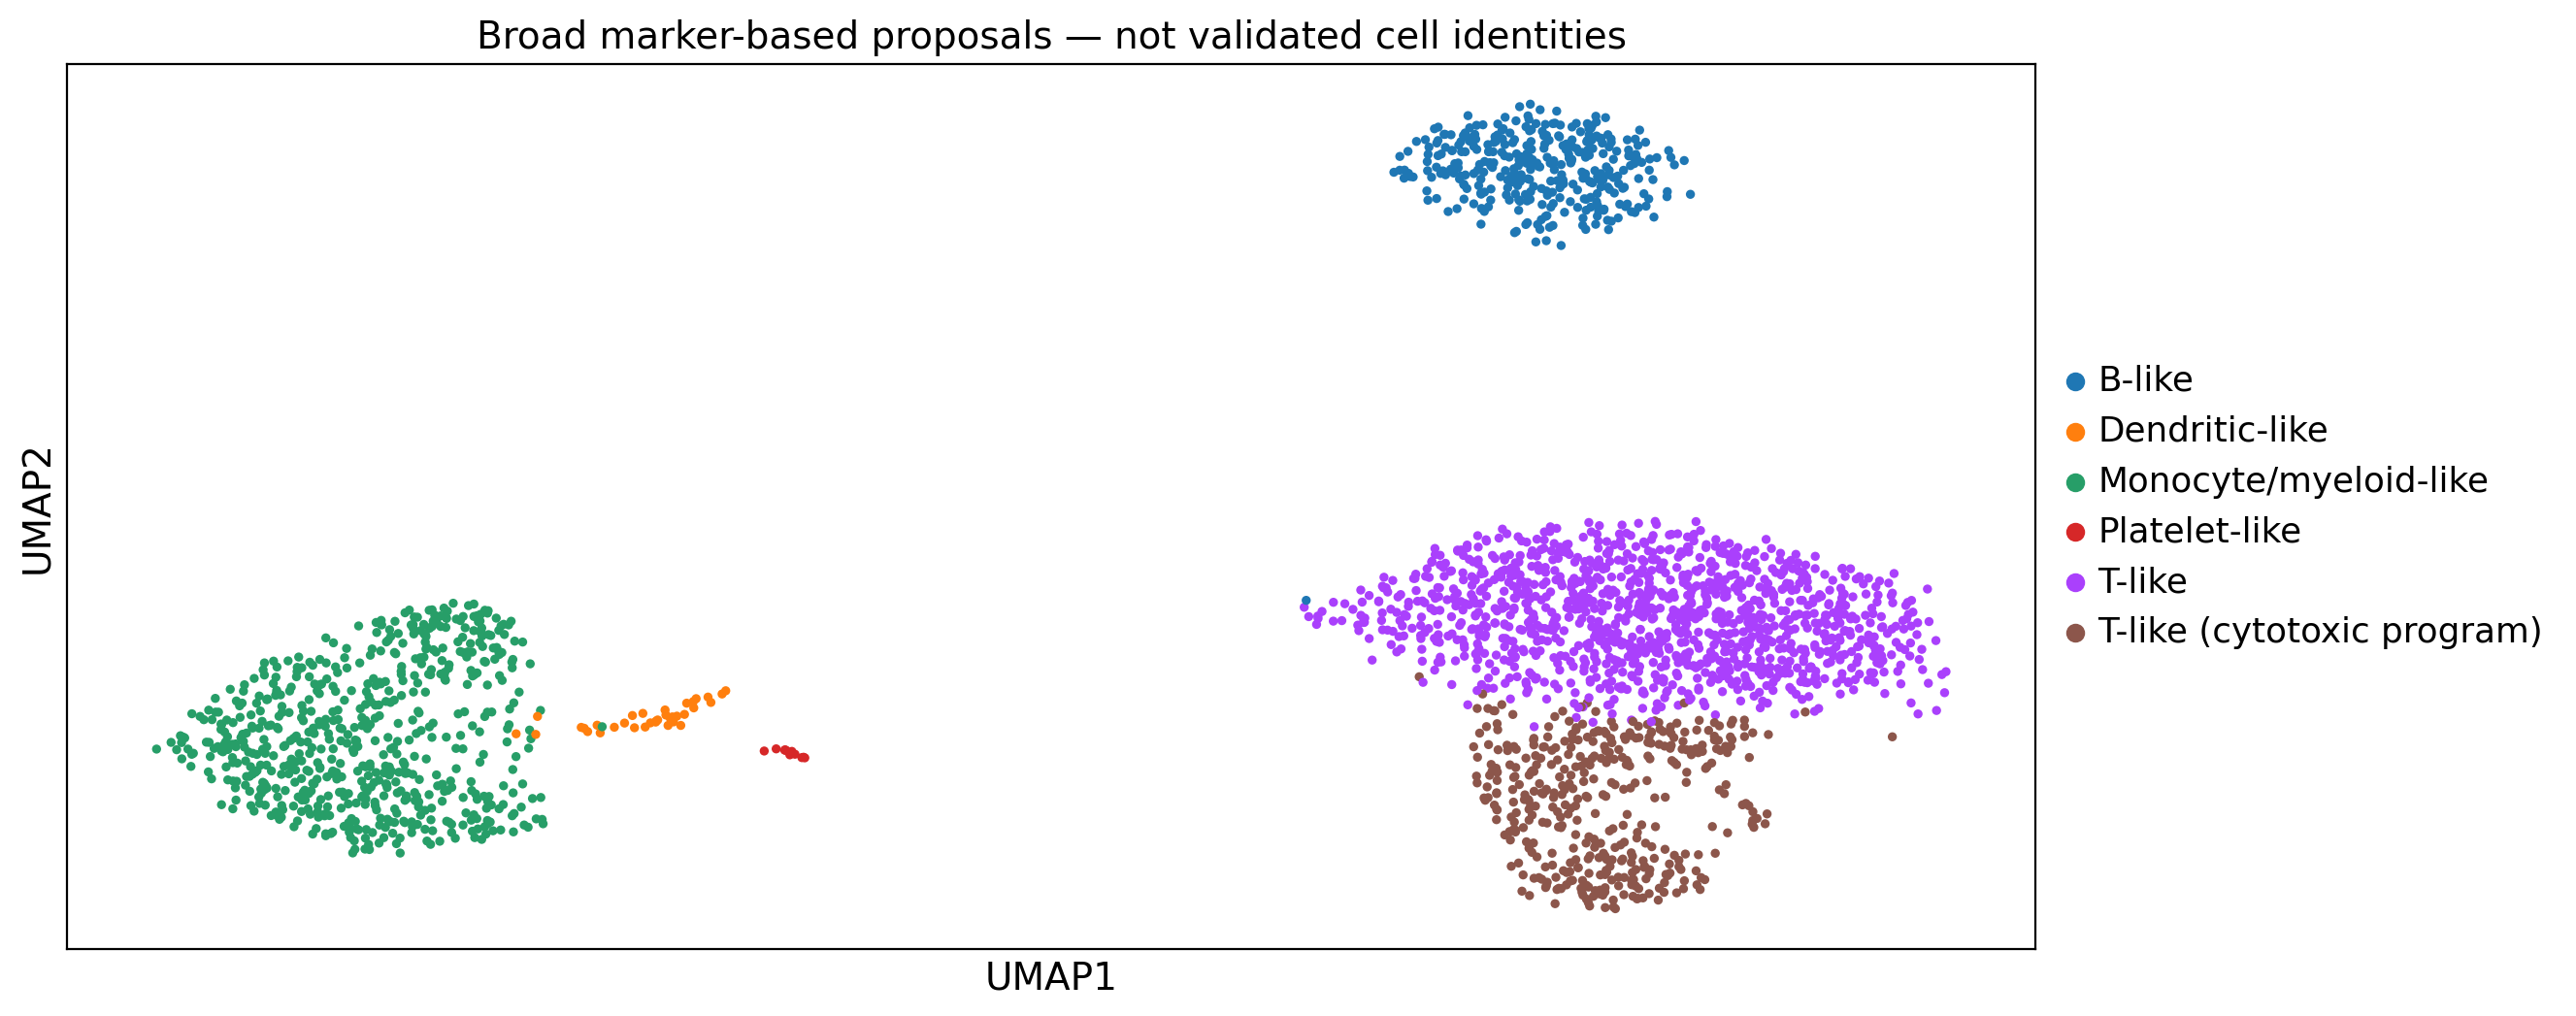

In [9]:
def propose_identity(cluster_evidence):
    """Conservative, auditable rules. Returns (proposal, status, evidence)."""
    e = cluster_evidence.set_index("gene")
    def supports(gene):
        return gene in e.index and e.loc[gene, "fraction_detected"] >= .20 and e.loc[gene, "mean_difference"] >= .15
    def hits(genes):
        return [g for g in genes if supports(g)]
    t = hits(["CD3D", "CD3E", "IL7R", "CD8A"])
    b = hits(["MS4A1", "CD79A"])
    myeloid = hits(["LYZ", "CD14", "FCGR3A", "MS4A7"])
    cyto = hits(["NKG7", "GNLY"])
    dc = hits(["FCER1A", "CST3"])
    platelet = hits(["PPBP", "PF4"])
    candidates = []
    if len(t) >= 2 and any(g in t for g in ["CD3D", "CD3E"]):
        candidates.append("T-like (cytotoxic program)" if len(cyto) >= 2 else "T-like")
    if len(b) >= 2:
        candidates.append("B-like")
    if len(myeloid) >= 2 and any(g in myeloid for g in ["LYZ", "CD14", "MS4A7"]):
        candidates.append("Monocyte/myeloid-like")
    if len(dc) >= 2:
        candidates.append("Dendritic-like")
    if len(platelet) >= 2:
        candidates.append("Platelet-like")
    cd3_fractions = [float(e.loc[g, "fraction_detected"]) for g in ["CD3D", "CD3E"] if g in e.index]
    if len(cyto) >= 2 and not any(x.startswith("T-like") for x in candidates):
        if len(cd3_fractions) == 2 and np.mean(cd3_fractions) < .20:
            candidates.append("NK-like")
        else:
            candidates.append("Cytotoxic lymphoid (T/NK uncertain)")
    evidence = "; ".join(g for g in e.index if supports(g))
    if len(candidates) == 0:
        return "Unassigned / insufficient marker evidence", "uncertain", evidence
    if len(candidates) > 1:
        return "Mixed/uncertain: " + " + ".join(candidates), "mixed/uncertain", evidence
    status = "uncertain" if "uncertain" in candidates[0] else "provisional; not validated"
    return candidates[0], status, evidence

panel_genes = list(dict.fromkeys(g for genes in present_panels.values() for g in genes))
matrix = adata[:, panel_genes].X.toarray()
annotation_tables = {}
all_evidence = []
for key in KEYS:
    rows = []
    labels = adata.obs[key].astype(str)
    for cluster in adata.obs[key].cat.categories:
        inside = (labels == str(cluster)).to_numpy()
        means = matrix[inside].mean(axis=0)
        rest_means = matrix[~inside].mean(axis=0)
        detection = (matrix[inside] > 0).mean(axis=0)
        evidence = pd.DataFrame({"resolution_key": key, "cluster": str(cluster),
            "gene": panel_genes, "mean_log_expression": means,
            "rest_mean_log_expression": rest_means, "mean_difference": means-rest_means,
            "fraction_detected": detection, "fraction_detected_rest": (matrix[~inside] > 0).mean(axis=0)})
        all_evidence.append(evidence)
        proposal, status, supporting = propose_identity(evidence)
        top = marker_tables[key].loc[marker_tables[key].group == str(cluster), "names"].head(5).tolist()
        rows.append(dict(cluster=str(cluster), cells=int(inside.sum()), proposed_identity=proposal,
                         status=status, supporting_markers=supporting, top_ranked_genes="; ".join(top)))
    annotations = pd.DataFrame(rows)
    annotation_tables[key] = annotations
    annotations.to_csv(TABLE / f"cluster_annotations_{key}.csv", index=False)
    mapping = annotations.set_index("cluster")["proposed_identity"].to_dict()
    adata.obs[f"identity_{key}"] = pd.Categorical(labels.map(mapping))
    adata.obs[f"annotation_status_{key}"] = labels.map(annotations.set_index("cluster")["status"])
    print(annotations.to_string(index=False))
pd.concat(all_evidence, ignore_index=True).to_csv(TABLE / "marker_panel_evidence.csv", index=False)
low_map = annotation_tables[KEYS[0]].set_index("cluster")["proposed_identity"]
high_map = annotation_tables[KEYS[1]].set_index("cluster")["proposed_identity"]
stability["low_proposed_identity"] = stability.low_cluster.map(low_map)
stability["dominant_high_proposed_identity"] = stability.dominant_high_cluster.map(high_map)
stability["substantial_children"] = [
    "; ".join(f"{child}: {fractions.loc[parent, child]:.1%} ({high_map[child]})"
              for child in cross.columns if fractions.loc[parent, child] >= CFG["split_fraction"])
    for parent in stability.low_cluster]
stability.to_csv(TABLE / "cluster_stability_annotated.csv", index=False)
print("Population-level interpretation (all identities provisional):")
print(stability[["low_cluster", "low_proposed_identity", "change", "substantial_children"]].to_string(index=False))
fig, ax = plt.subplots(figsize=(13, 6))
sc.pl.umap(adata, color=f"identity_{KEYS[0]}", ax=ax, show=False,
           title="Broad marker-based proposals — not validated cell identities")
save_figure(fig, "umap_provisional_identities")


## Cell 10 — Export and verify a real completed run
The first retained cell is traced using its actual barcode and count values.
Outputs include input counts, the processed `.h5ad`, per-cell annotations,
complete marker tables, QC reports, figures, graph-overlap results, and the
resolved environment. Reloading the `.h5ad` checks that labels and counts survive.
Only after these checks does the run status change to `complete`.

**Limits:** one donor/sample; no disease, treatment, or independent validation
groups. No population-level clinical conclusions, causal claims, or wet-lab
experience. Ambient RNA, doublets, dropout, technical variation, and filtering
bias remain possible. Only resolution sensitivity was tested; seed/QC/HVG/PCA
sensitivity, formal doublet detection, reference mapping, and protein validation
are future work. A stable cluster is not necessarily a correct cell type.


In [10]:
adata.uns["project_config"] = CFG
adata.uns["provenance"] = {
    "dataset": "10x Genomics PBMC3k, one healthy donor, Cell Ranger 1.1.0",
    "source": "https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-1-0",
    "data_license": "CC BY 4.0", "count_location": "layers/counts",
    "X_semantics": "log1p library-size-normalized expression over retained genes",
    "annotations": "heuristic cluster-level proposals, not validated cell types"}
assert sparse_fingerprint(adata.layers["counts"]) == count_fingerprint
assert sparse_fingerprint(adata.obsp["connectivities"]) == graph_fingerprint
assert np.isfinite(adata.obsm["X_pca"]).all() and np.isfinite(adata.obsm["X_umap"]).all()
adata.obs.to_csv(TABLE / "cell_annotations.csv", index_label="cell_barcode")
adata.write_h5ad(RUN / "pbmc3k_processed.h5ad", compression="gzip")
reloaded = sc.read_h5ad(RUN / "pbmc3k_processed.h5ad")
assert reloaded.shape == adata.shape
assert reloaded.obs_names.equals(adata.obs_names) and reloaded.var_names.equals(adata.var_names)
assert sparse_fingerprint(reloaded.layers["counts"]) == count_fingerprint
for key in KEYS:
    assert reloaded.obs[key].equals(adata.obs[key])
    assert reloaded.obs[f"identity_{key}"].equals(adata.obs[f"identity_{key}"])
example_gene = "CD3D" if "CD3D" in adata.var_names else adata.var_names[0]
gene_index = adata.var_names.get_loc(example_gene)
cell_total = float(adata.layers["counts"][0].sum())
gene_count = float(adata.layers["counts"][0, gene_index])
expected_log = float(np.log1p(gene_count / cell_total * CFG["target_sum"]))
observed_log = float(adata.X[0, gene_index])
assert np.isclose(expected_log, observed_log, rtol=1e-5, atol=1e-6)
cell_trace = {"barcode": str(adata.obs_names[0]), "gene": example_gene,
    "raw_gene_count": gene_count, "retained_gene_total_counts": cell_total,
    "total_counts_before_gene_filter": float(adata.obs.iloc[0].total_counts),
    "detected_genes_before_gene_filter": int(adata.obs.iloc[0].n_genes_by_counts),
    "mitochondrial_pct_before_gene_filter": float(adata.obs.iloc[0].pct_counts_mt),
    "normalized_gene_count": gene_count / cell_total * CFG["target_sum"],
    "log1p_gene_expression": observed_log, "gene_is_hvg": bool(adata.var.iloc[gene_index].highly_variable),
    "first_three_PCs": adata.obsm["X_pca"][0, :3].astype(float).tolist(),
    "UMAP": adata.obsm["X_umap"][0].astype(float).tolist(),
    "clusters": {key: str(adata.obs.iloc[0][key]) for key in KEYS},
    "proposed_identity": str(adata.obs.iloc[0][f"identity_{KEYS[0]}"])}
write_json(RUN / "one_cell_trace.json", cell_trace)
observations = ["# Measured run observations", "", f"Run: {RUN.name}",
    f"Retained {adata.n_obs:,} of {summary['input_cells']:,} cells and {adata.n_vars:,} genes.",
    f"Selected {int(adata.var.highly_variable.sum()):,} highly variable genes.",
    f"Leiden 0.4: {sensitivity['clusters_at_0_4']} clusters; Leiden 0.8: {sensitivity['clusters_at_0_8']} clusters.",
    f"Adjusted Rand index: {ari:.6f}.", "", "## Membership stability", ""]
for row in stability.itertuples():
    observations.append(f"- Low cluster {row.low_cluster} ({row.low_proposed_identity}): {row.change}; "
        f"dominant fraction {row.dominant_fraction:.1%}, child purity {row.dominant_child_purity:.1%}. "
        f"Substantial children: {row.substantial_children}.")
observations += ["", "All identities are provisional marker-based proposals. These results do not establish disease effects,",
                 "independent biological validation, or generalization across donors.", "",
                 "Neither resolution was selected by plot attractiveness; 0.4 is the declared broad-summary view."]
(RUN / "OBSERVATIONS.md").write_text("\n".join(observations), encoding="utf-8")
(RUN / "DATA_ATTRIBUTION.txt").write_text(
    "Source: 10x Genomics, 3k PBMCs from a Healthy Donor (2016), Cell Ranger 1.1.0.\n"
    + adata.uns["provenance"]["source"] + "\nLicense: https://creativecommons.org/licenses/by/4.0/\n"
    "Derived changes: QC filtering, gene filtering, normalization, PCA, graph, clustering, visualization, annotations.\n"
    "Workflow adapted from Scanpy PBMC3k tutorial. Wolf et al. (2018), doi:10.1186/s13059-017-1382-0.\n",
    encoding="utf-8")
write_json(RUN / "run_status.json", {"status": "complete", "pbmc_analysis_complete": True,
    "elapsed_seconds": round(time.perf_counter()-START, 2), "h5ad_roundtrip_passed": True,
    "count_preservation_passed": True, "same_graph_passed": True,
    "one_cell_normalization_check_passed": True})
print("\n".join(observations))
print("One-cell trace:", json.dumps(cell_trace, indent=2))
print("COMPLETE — exports:", RUN)


# Measured run observations

Run: run_20261020T174202_091744Z
Retained 2,638 of 2,700 cells and 13,656 genes.
Selected 2,000 highly variable genes.
Leiden 0.4: 6 clusters; Leiden 0.8: 8 clusters.
Adjusted Rand index: 0.679747.

## Membership stability

- Low cluster 0 (T-like): split across >=2 substantial groups; dominant fraction 65.5%, child purity 99.9%. Substantial children: 0: 65.5% (T-like); 3: 32.3% (T-like).
- Low cluster 1 (Monocyte/myeloid-like): split across >=2 substantial groups; dominant fraction 75.8%, child purity 100.0%. Substantial children: 1: 75.8% (Monocyte/myeloid-like); 5: 23.8% (Monocyte/myeloid-like).
- Low cluster 2 (T-like (cytotoxic program)): stable one-to-one; dominant fraction 99.5%, child purity 94.0%. Substantial children: 2: 99.5% (T-like (cytotoxic program)).
- Low cluster 3 (B-like): stable one-to-one; dominant fraction 100.0%, child purity 100.0%. Substantial children: 4: 100.0% (B-like).
- Low cluster 4 (Dendritic-like): stable one-to-one; dominan

## Cell 11 — Optional Colab download
Run this after cell 10 reports COMPLETE. The archive contains only this run.
Download the executed notebook separately using Colab **File → Download → .ipynb**
if you want to retain its visible outputs as well.


In [11]:
import shutil
archive = shutil.make_archive(str(RUN), "zip", root_dir=RUN)
print("Results archive:", archive)
if "google.colab" in sys.modules:
    from google.colab import files
    files.download(archive)


Results archive: /content/pbmc3k_runs/run_20261020T174202_091744Z.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>